# Figure S24 - PENGUIN on long-timescale molecular dynamics of Ash1

Lotthammer, J. M. & Holehouse, A. S. *Disentangling folding from energetic traps in simulations of disordered proteins.* **J. Chem. Inf. Model.** (2025). doi:[10.1021/acs.jcim.4c02005](https://doi.org/10.1021/acs.jcim.4c02005)

**What the figure shows.** The same Ash1 fragment as Figure 7, but from a single long all-atom molecular dynamics trajectory (D. E. Shaw Research) rather than Monte Carlo replicates. Because there is only one trajectory, it is cut into five equal, contiguous segments that are treated as pseudo-replicates. Panels B-E are the standard PENGUIN summary; panel F (SAXS back-calculation) is not reproduced here.

**What to look for.** The MD segments agree with one another (all-to-all ≈ 0.1-0.3, panel C) so the trajectory is internally consistent, but every residue sits far from the tabulated EV limit (≈ 0.85-0.9, panel B) - much further than the Monte Carlo Ash1 ensemble of Figure 7. This matches the published S24 and reflects a genuine difference between the all-atom force field's backbone distributions and the CAMPARI-derived EV tables, so panel B here says more about the reference than about sampling; the all-to-all panel is the informative one. Splitting one trajectory into segments is a useful trick when independent replicates are unavailable, with the caveat that consecutive segments are not truly independent.

**Uncapped chain.** Unlike every other system here, `full.pdb` has no ACE/NME caps, so the first residue has no φ and the last has no ψ. SOURSOP 2.0.6 restricts the analysis to the 81 interior residues that carry both angles (`SamplingQuality.residue_indices`); earlier versions paired φ of residue *k+1* with ψ of residue *k* on uncapped chains. The x-axis therefore runs from residue 2 to 82.

**No EV simulations for this system.** As in notebook 10, the reference is SOURSOP's precomputed EV distribution, so the 2.0.6 corrections to that path (see notebook 10) apply here too.

**Data.** `data/ash1_md/full/1..5/__traj.xtc` (34,000 frames each) sharing the topology `data/ash1_md/full/full.pdb`. The paper's repository shows a version built from three of the five segments (an artefact of how the files were discovered); all five are used here.

## Setup

All notebooks in this directory share `penguin_helpers.py`, a thin layer over SOURSOP's public `soursop.sssampling.SamplingQuality` API that handles data discovery, the manuscript's matplotlib style, and the four-panel PENGUIN figure. The trajectories (~6 GB) live in `data/`, one folder per system with `full/` and `ev/` replicates (see `data/README.md`); they are too large for the SOURSOP repository, so set `PENGUIN_DATA_DIR` if you keep them elsewhere.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from penguin_helpers import (
    set_manuscript_style, get_data_dir, figure_path, load_system,
    penguin_figure, print_sequence,
)

set_manuscript_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

DATA_DIR = get_data_dir()
print("Reading simulation data from", DATA_DIR)
from soursop.sssampling import SamplingQuality

Reading simulation data from /Users/alex/Dropbox/WASHU/Holehouse/tools/soursop/soursop/demo_examples/penguin/data


## Load the five segments

In [2]:
ash1_dir = DATA_DIR / "ash1_md" / "full"
segments = [str(ash1_dir / str(i) / "__traj.xtc") for i in range(1, 6)]
ash1_md = SamplingQuality(segments, top_file=str(ash1_dir / "full.pdb"),
                          method="2D angle distributions", seed=0)
sequence = print_sequence(ash1_md)
print("phi array (segments, residues, frames):", ash1_md.phi_angles.shape)

GASASSSPSPSTPTKSGKMRSRSSSPVRPKAYTPSPRSPNYHRFALDSPPQSPRRSSNSSITKKGSRRSSGSSPTRHTTRVCV
.........1.........2.........3.........4.........5.........6.........7.........8...
phi array (segments, residues, frames): (5, 81, 34000)


## How to read a PENGUIN figure

Every PENGUIN summary has the same four panels (the sequence cartoon shown as panel **A** in the paper was drawn in a vector graphics editor, so here we print the sequence with a ruler instead):

* **B - Comparison to the excluded-volume limit.** For every residue and every full-Hamiltonian (FH) replicate, the joint (φ, ψ) distribution is histogrammed and compared to the same residue in the excluded-volume (EV) reference ensemble using the Hellinger distance (0 = identical, 1 = no overlap). Red points are individual replicates; the black line is the replicate mean. Low values mean the residue explores its backbone conformational space about as freely as a chain with no attractive interactions; high values mean the FH ensemble is restricted relative to that limit - which can be genuine structure *or* an energetic trap.
* **C - All-to-all trajectory comparison.** The same Hellinger distance, but between every pair of FH replicates. If independent replicates agree with one another (low values) the restriction seen in **B** is reproducible and therefore reflects the Hamiltonian; if they disagree (high values) each replicate is stuck somewhere different - the signature of poor sampling.
* **D - Spread of B.** The maximum minus minimum Hellinger distance across replicates, per residue; a compact summary of how consistently a residue is scored against the EV limit.
* **E - Fractional helicity.** Per-residue DSSP helicity of the FH replicates, so that any restriction in **B** can be checked against a concrete structural explanation.

The logic of the method is that **B** on its own cannot distinguish folding from trapping, but **B** together with **C** can: reproducible structure gives high **B** / low **C**, whereas energetic traps give high **B** / high **C**.

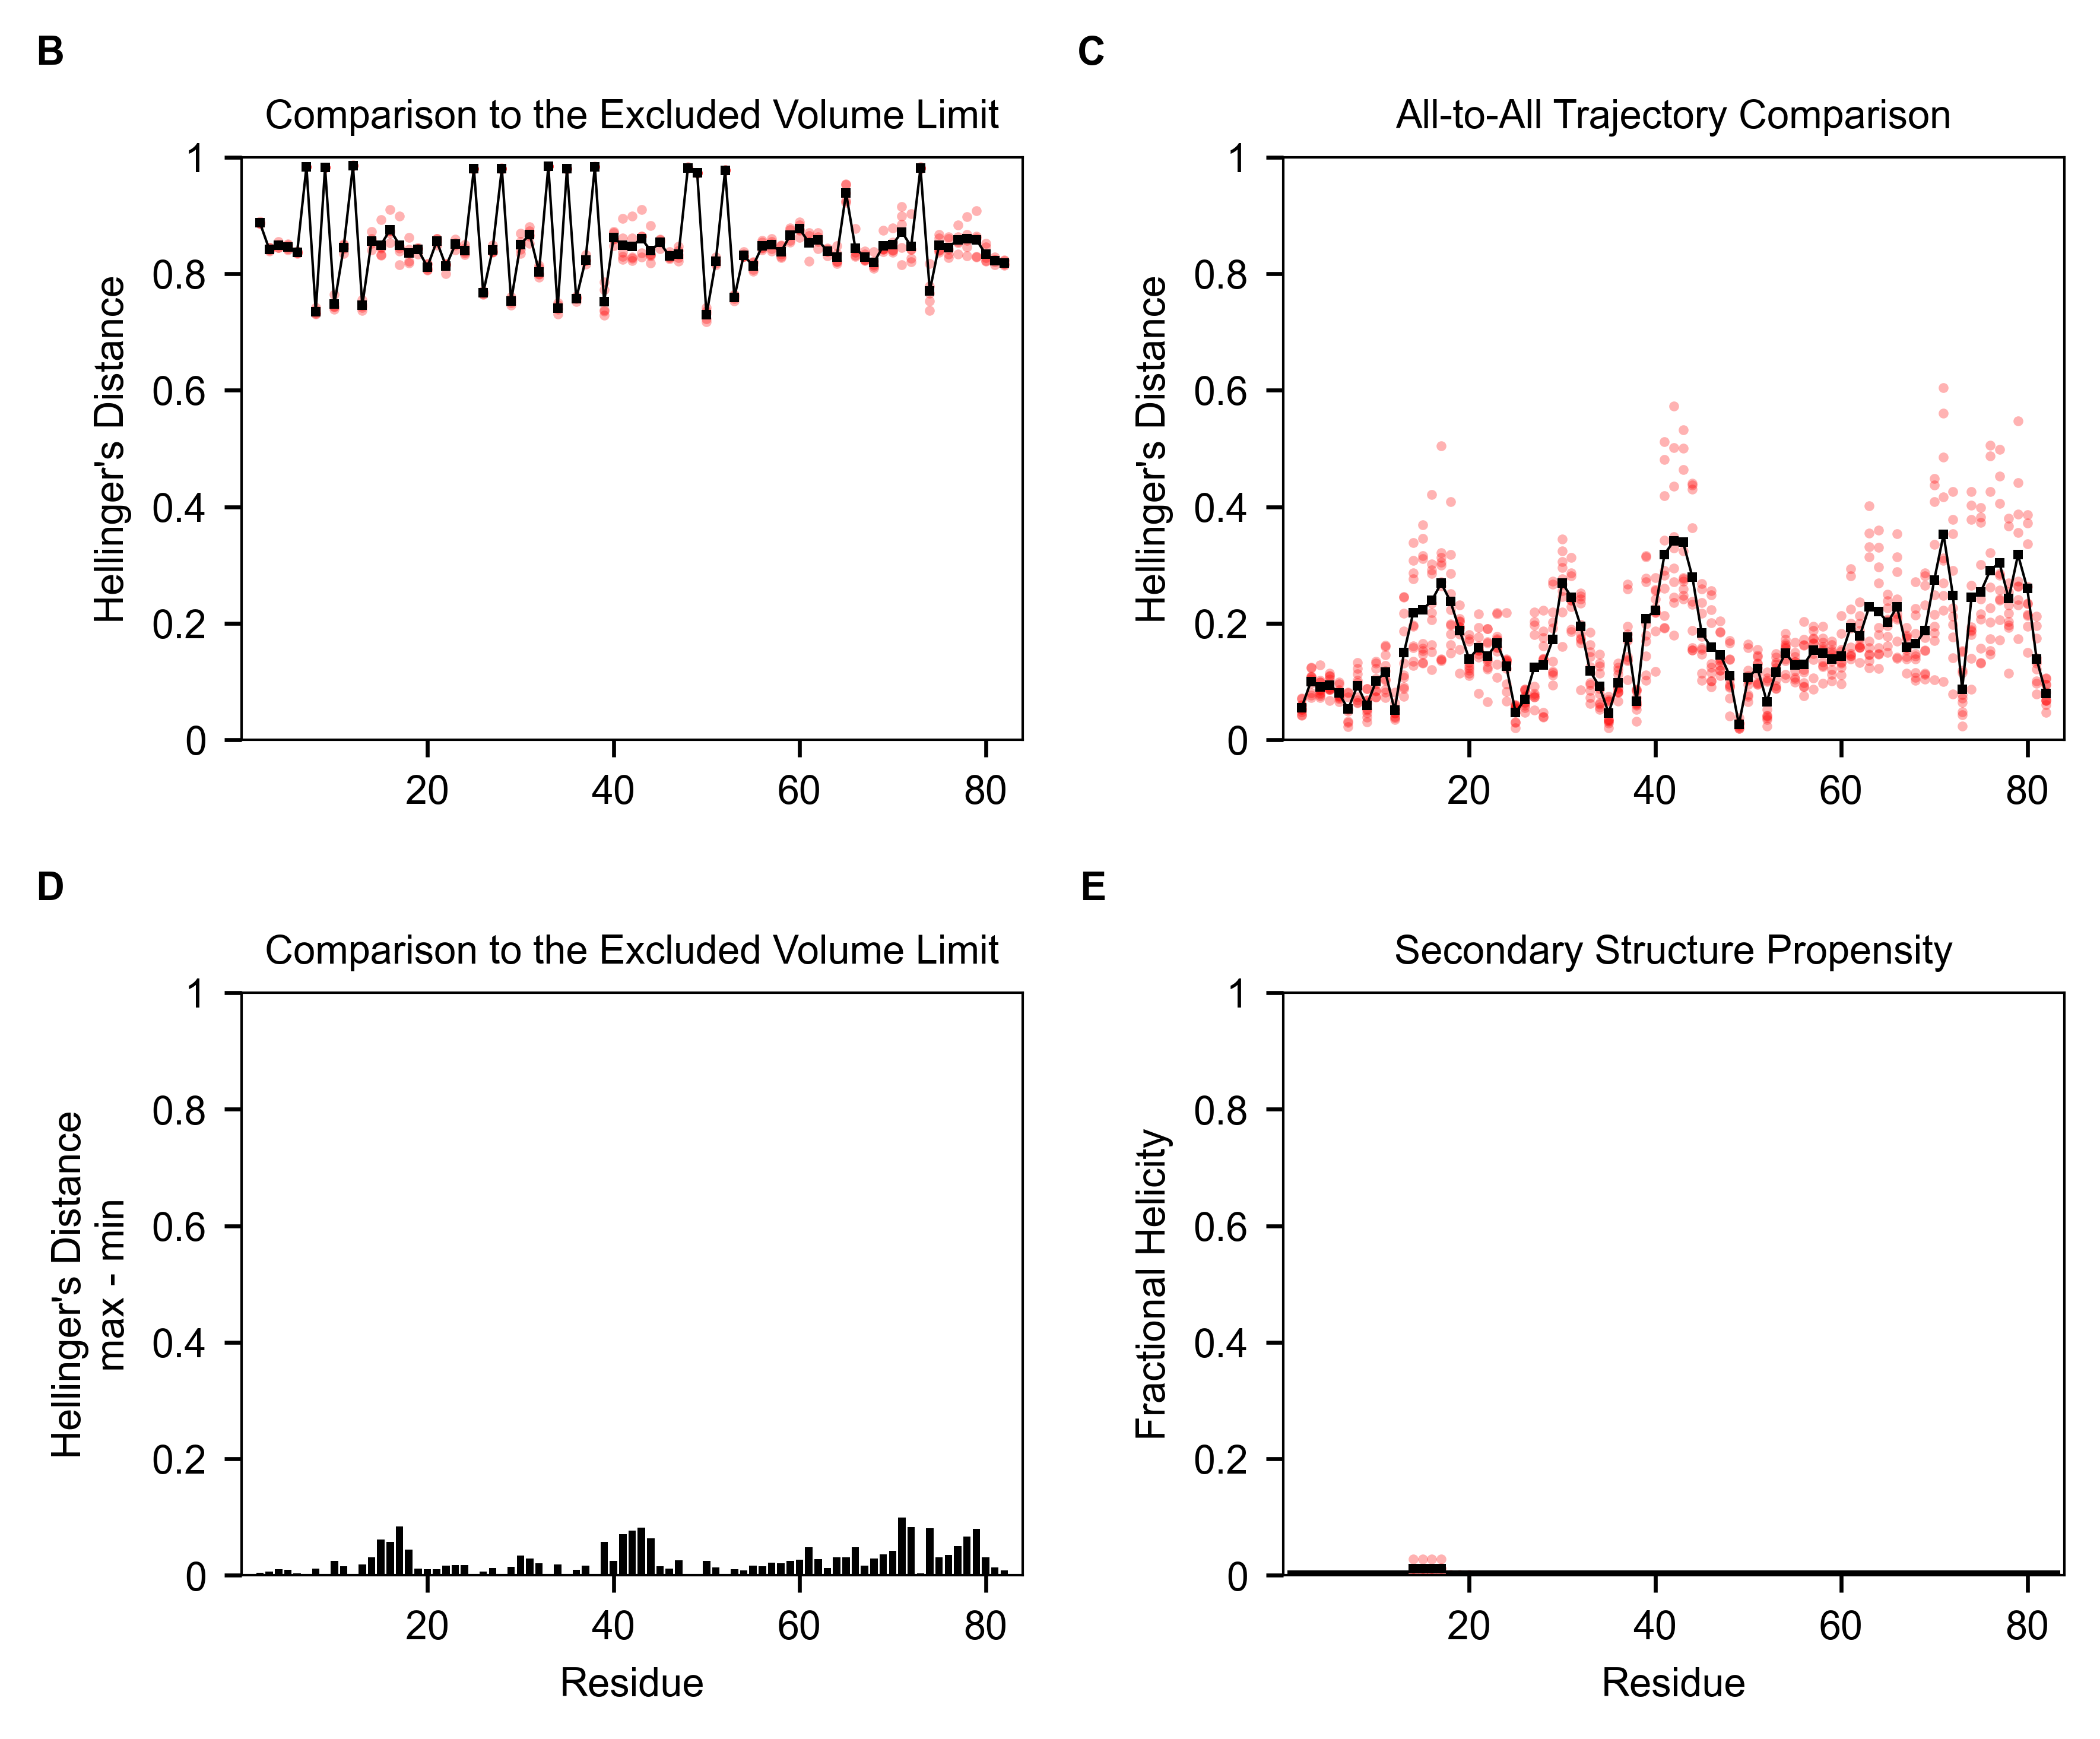

In [3]:
fig, axd = penguin_figure(ash1_md, dihedral="2D", increment=20, figsize=(6, 5), fontsize=8,
                          label_position=(-0.1, 1.15), panel_labels=("B", "C", "D", "E"),
                          save_path=figure_path("si_figures", "ash1_md_5segments_2D_hellingers.pdf"))